In [123]:
from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
%matplotlib widget
import logging
logging.basicConfig(level=logging.ERROR)
import pickle
import cv2
import torch
import os

from nntool.utils.stats_funcs import qsnr

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from decoding_layer import decoding

sys.path.append("../../../YOLOX")
from yolox.data.data_augment import preproc as preprocess
from yolox.utils import multiclass_nms, demo_postprocess, vis
from yolox.data.datasets import COCO_CLASSES

In [2]:
class YOLOXCOCODaset(CostomCOCODaset):
    def __init__(
        self, 
        image_folder, 
        annotations, 
        input_size,
        max_size=500, 
        transpose_to_chw=True,
        input_channels=3,
        img_type = "rgb",
        enable_slicing=True
        ):

        self._img = None
        self._ratio = 1
        super().__init__(
            image_folder, annotations, input_size, max_size, transpose_to_chw,
            input_channels, img_type, enable_slicing
        )

    def __iter__(self):
        self._idx = 0
        return self

    def __next__(self):

        if self._idx >= self.max_idx:
            raise StopIteration()

        filename = self.annotations[self._idx]["file_name"]

        if self.img_type == "bayer":
            filename = filename.replace("jpg", "png")
        img_file = os.path.join(self.data_dir, filename)

        # read image as BGR
        image = cv2.imread(
            img_file,
            cv2.IMREAD_UNCHANGED
        )
        if image is None:
            img_file = img_file.replace(".jpg", ".ppm").replace(".jpeg", ".ppm")
            image = cv2.imread(
                img_file,
                cv2.IMREAD_UNCHANGED
            )

        if self.transpose_to_chw:
            swap = (2, 0, 1)
        else:
            swap = (0, 1, 2)

        self._img = image
        processed_img, self._ratio = preprocess(image.copy(), self.input_size, swap)

        self._idx += 1
        return processed_img[None] 
    
    def __len__(self):
        return self.max_idx

In [3]:
def post_process(model_out, ratio, input_shape, score_thr=0.11):
    predictions = demo_postprocess(model_out[0].copy()[None, :], input_shape)[0]

    boxes = predictions[:, :4]
    scores = predictions[:, 4:5] * predictions[:, 5:]

    boxes_xyxy = np.ones_like(boxes)
    boxes_xyxy[:, 0] = boxes[:, 0] - boxes[:, 2]/2.
    boxes_xyxy[:, 1] = boxes[:, 1] - boxes[:, 3]/2.
    boxes_xyxy[:, 2] = boxes[:, 0] + boxes[:, 2]/2.
    boxes_xyxy[:, 3] = boxes[:, 1] + boxes[:, 3]/2.
    boxes_xyxy /= ratio
    dets = multiclass_nms(boxes_xyxy, scores, nms_thr=0.45, score_thr=score_thr)
    return dets

In [89]:
G = NNGraph.load_graph("../../../yolox_people_detection/weights/model.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")

model:
	Max Active Size:	614400 elements
	Total # Parameters:	889058 elements
	Total # Operations:	230.33 MOps


In [90]:
## fix the order of the last layer to match that in pytorch 
G[-1].fixed_order = True

G.adjust_order()
G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

In [96]:
annotations = get_annotations("../../../yolox_people_detection/datasets/annotations/instances_val2017.json")
# calculate statistics
quant_dataset = CostomCOCODaset(
    image_folder     = "../../../yolox_people_detection/datasets/val2017",
    annotations      = annotations,
    max_size         = 100,
    input_size       = (240, 320),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = True
)

Loading annotations for class person...
loading annotations into memory...
Done (t=0.37s)
creating index...
index created!


In [97]:
G.inputs_dim[0]

[1, 12, 120, 160]

In [98]:
stats = G.collect_statistics(quant_dataset)

with open("precalculated_stats_baseline_gap9.pickle", "wb") as f:
    pickle.dump(stats, f)

In [8]:
# with open("precalculated_stats_baseline.pickle", "rb") as f:
#     stats = pickle.load(f)

In [99]:
G.quantize(
    stats,
    graph_options={
        'bits': 8,
        'quantized_dimension': 'channel',
        'use_ne16': True,
        'hwc': True,
    },

    node_options= {
        'output_1' : 
            {
                'scheme' : 'float', 
                'float_type': 'float32'
            },
    },
)

In [100]:
sample = next(iter(quant_dataset))

In [101]:
sample.shape

(1, 12, 120, 160)

In [102]:
sample = sample.transpose(0, 2, 3, 1)

In [103]:
qfout = G.execute([sample], quantize=True, dequantize=True)
fout  = G.execute([sample], quantize=False, dequantize=False)

for i, fp32, fp16 in zip(range(len(G)), fout, qfout):
    print(f"Graph[{i:3}] -> {G[i].name:>40}:\t{qsnr(fp32[0], fp16[0])}")

Graph[  0] ->                                  input_1:	inf
Graph[  1] ->                        Conv_0_reshape_in:	inf
Graph[  2] ->                           Conv_0_weights:	44
Graph[  3] ->                           constant__1247:	109
Graph[  4] ->                            Conv_0_fusion:	42
Graph[  5] ->                           Conv_4_weights:	48
Graph[  6] ->                           constant__1250:	80
Graph[  7] ->                            Conv_4_fusion:	35
Graph[  8] ->                           Conv_8_weights:	44
Graph[  9] ->                           constant__1253:	92
Graph[ 10] ->                            Conv_8_fusion:	24
Graph[ 11] ->                          Conv_12_weights:	44
Graph[ 12] ->                           constant__1256:	90
Graph[ 13] ->                           Conv_12_fusion:	22
Graph[ 14] ->                          Conv_16_weights:	44
Graph[ 15] ->                           constant__1259:	94
Graph[ 16] ->                           Conv_16_fusio

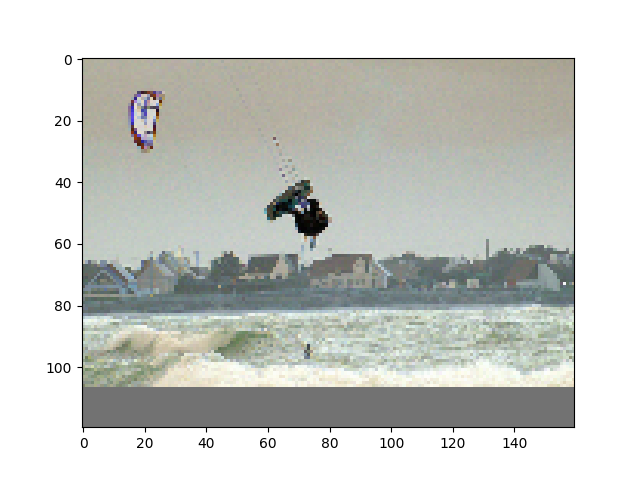

In [113]:
tmp = sample[0].astype(np.uint8)
tmp.shape
tmp_img = tmp[:, :, :3].copy()

plt.figure()
plt.imshow(tmp_img)
plt.show()

In [114]:
float_out = [fout[out_node.step_idx][0] for out_node in G.outputs()]
quant_out = [qfout[out_node.step_idx][0] for out_node in G.outputs()]

In [118]:
float_out[0].shape, quant_out[0].shape

((1580, 6), (1580, 6))

In [136]:
strides = [8, 16, 32]
feature_map_sizes = [(8, 8), (4, 4), (2, 2)]
# feature_map_sizes = [(32, 40), (16, 20), (8, 10)]

In [137]:
outputs_1 = decoding.decode_C_style(float_out[0].copy(), feature_map_sizes, strides)

In [140]:
outputs_1

array([[ 6.3588161e+00,  1.1157546e+01,  5.1106501e-01,  7.2652397e+00,
         1.7578203e-06,  2.5243547e+00],
       [ 4.6146698e+00,  1.1541222e+01,  8.0414610e+00,  7.5732574e+00,
         1.9889816e-07,  2.1776631e+00],
       [ 8.9476738e+00,  2.4572016e+01,  2.6735929e+01,  1.4588520e+01,
         8.0000019e+00,  1.0870311e+01],
       ...,
       [ 4.4126093e-01,  4.7759512e-01, -8.7044030e-01, -2.6778567e-01,
         1.3426005e-05,  1.7818520e-02],
       [ 4.4662797e-01,  4.8652557e-01, -8.2857490e-01, -2.7715912e-01,
         1.4095949e-05,  1.7818520e-02],
       [ 4.5363769e-01,  4.8636284e-01, -7.7182841e-01, -2.5595993e-01,
         2.2185717e-05,  1.7818520e-02]], dtype=float32)